In [2]:
import pandas as pd
import numpy as np

# Load the dataset (replace with your actual file path)
df = pd.read_csv("final_merged_energy_weather_data.csv")

# Display basic info
print("Data Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

# Check for missing values
print("\nMissing Values per Column:")
print(df.isnull().sum())

# Check unique cities (ensure all 10 are present)
print("\nUnique Cities:", df['city'].unique())

C:\Users\lab\AppData\Local\Temp\ipykernel_17736\1909659684.py:5: DtypeWarning: Columns (1,10,15,17,29,44,45,46,47,49,51,53,55,57,58,59,60,61,62,63,64) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("final_merged_energy_weather_data.csv")


Data Shape: (199429, 65)

First 5 Rows:


,company,region,demand,datetime,utc_time,city,apparentTemperature,cloudCover,dewPoint,humidity,...,pressure_anomaly_z,dewPoint_zscore,dewPoint_anomaly_z,temperature_anomaly_iqr,humidity_anomaly_iqr,windSpeed_anomaly_iqr,pressure_anomaly_iqr,dewPoint_anomaly_iqr,anomaly_iso,is_anomaly
0,AZPS,NaN,3497.0,2018-07-01 01:00:00,2018-07-01 08:00:00,phoenix,63.19,0.31,49.53,0.69,...,NaN,0.815363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AZPS,NaN,3256.0,2018-07-01 02:00:00,2018-07-01 09:00:00,phoenix,63.19,0.31,49.53,0.69,...,NaN,0.815363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AZPS,NaN,3065.0,2018-07-01 03:00:00,2018-07-01 10:00:00,phoenix,63.19,0.31,49.53,0.69,...,NaN,0.815363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AZPS,NaN,2929.0,2018-07-01 04:00:00,2018-07-01 11:00:00,phoenix,63.19,0.31,49.53,0.69,...,NaN,0.815363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AZPS,NaN,2833.0,2018-07-01 05:00:00,2018-07-01 12:00:00,phoenix,63.19,0.31,49.53,0.69,...,NaN,0.815363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values per Column:
company                      0
region                   93113
demand                       0
datetime                     0
utc_time                     0
                         ...  
windSpeed_anomaly_iqr    70751
pressure_anomaly_iqr     70751
dewPoint_anomaly_iqr     70751
anomaly_iso              70751
is_anomaly               70751
Length: 65, dtype: int64

Unique Cities: ['phoenix' 'seattle' 'nyc' 'la' 'philadelphia' 'san diego' 'san jose'
 'houston' 'san antonio' 'dallas']


In [3]:
# Drop rows with missing critical features (e.g., demand, temperature)
df.dropna(subset=['demand', 'temperature', 'humidity'], inplace=True)

# For less critical columns, impute with mean/median (example for windSpeed)
df['windSpeed'].fillna(df['windSpeed'].median(), inplace=True)

# Verify no missing values remain
print("Remaining Missing Values:")
print(df.isnull().sum())

Remaining Missing Values:
company                      0
region                   93113
demand                       0
datetime                     0
utc_time                     0
                         ...  
windSpeed_anomaly_iqr    70751
pressure_anomaly_iqr     70751
dewPoint_anomaly_iqr     70751
anomaly_iso              70751
is_anomaly               70751
Length: 65, dtype: int64


C:\Users\lab\AppData\Local\Temp\ipykernel_17736\3955950653.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['windSpeed'].fillna(df['windSpeed'].median(), inplace=True)


In [4]:
df.drop(columns=['region', 'utc_time'], inplace=True)  # Example columns
# Impute with median (robust to outliers)


In [5]:
numeric_cols = ['windSpeed_anomaly_iqr', 'pressure_anomaly_iqr', 'dewPoint_anomaly_iqr']
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
# Impute with mode (most frequent value)
df['company'] = df['company'].fillna(df['company'].mode()[0])
# Assume missing = not anomalous (False)
df['is_anomaly'] = df['is_anomaly'].fillna(0)
df.dropna(inplace=True)  # Only if <5% of data is lost
print("Remaining Missing Values:")
print(df.isnull().sum().sort_values(ascending=False))

Remaining Missing Values:
company                  0
demand                   0
datetime                 0
city                     0
apparentTemperature      0
                        ..
windSpeed_anomaly_iqr    0
pressure_anomaly_iqr     0
dewPoint_anomaly_iqr     0
anomaly_iso              0
is_anomaly               0
Length: 63, dtype: int64


In [6]:
# Convert 'datetime' to pandas datetime format
df['datetime'] = pd.to_datetime(df['datetime'])

# Extract time-based features
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek  # Monday=0, Sunday=6
df['month'] = df['datetime'].dt.month
df['season'] = df['month'] % 12 // 3 + 1  # 1:Winter, 2:Spring, etc.

# Normalize continuous variables (e.g., temperature, demand)
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df[['temperature_normalized', 'demand_normalized']] = scaler.fit_transform(df[['temperature', 'demand']])

# Display new features
print("\nEngineered Features:")
print(df[['datetime', 'hour', 'day_of_week', 'season', 'temperature_normalized']].head())


Engineered Features:
              datetime  hour  day_of_week  season  temperature_normalized
6  2018-07-01 07:00:00     7            6       3                0.753644
7  2018-07-01 08:00:00     8            6       3                0.722408
8  2018-07-01 09:00:00     9            6       3                0.711996
9  2018-07-01 10:00:00    10            6       3                0.694975
10 2018-07-01 11:00:00    11            6       3                0.685921


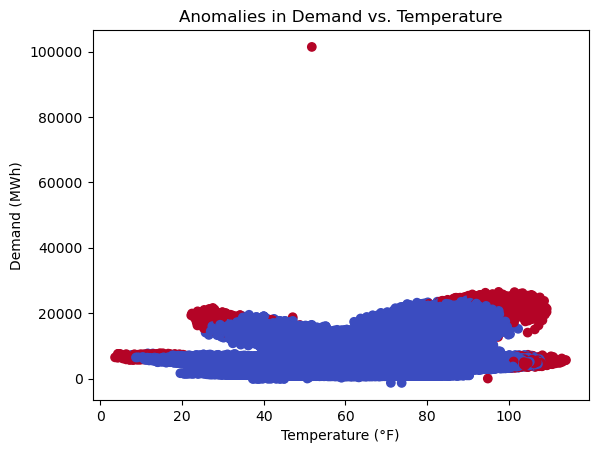

Number of Anomalies: 1287


In [7]:
from sklearn.ensemble import IsolationForest

# Detect anomalies in demand
model = IsolationForest(contamination=0.01, random_state=42)
df['is_anomaly'] = model.fit_predict(df[['demand', 'temperature', 'humidity']])
df['is_anomaly'] = df['is_anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Optional: Visualize anomalies (e.g., demand vs. temperature)
import matplotlib.pyplot as plt
plt.scatter(df['temperature'], df['demand'], c=df['is_anomaly'], cmap='coolwarm')
plt.xlabel('Temperature (°F)')
plt.ylabel('Demand (MWh)')
plt.title('Anomalies in Demand vs. Temperature')
plt.show()

print("Number of Anomalies:", df['is_anomaly'].sum())

In [8]:
# Group by city and hour to calculate median demand
median_demand = df.groupby(['city', 'hour'])['demand'].transform('median')

# Replace anomalous demand values with the median
df['demand'] = np.where(df['is_anomaly'] == 1, median_demand, df['demand'])

# Optional: Mark imputed values
df['demand_imputed'] = np.where(df['is_anomaly'] == 1, True, False)

In [9]:
# Dimensionality Reduction
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
# Clustering Algorithms
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
# Evaluation Metrics
from sklearn.metrics import silhouette_score
# Hierarchical Clustering Visualization
from scipy.cluster.hierarchy import dendrogram, linkage
# Miscellaneous
import warnings
warnings.filterwarnings('ignore')  # Suppress warnings for cleaner output

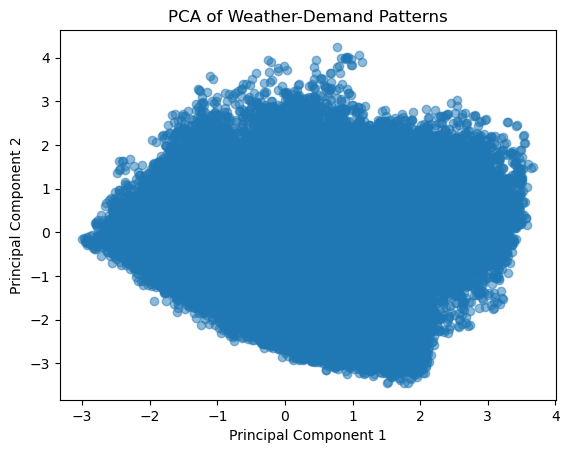

In [10]:

# Select features for clustering
features = ['temperature', 'humidity', 'windSpeed', 'demand']
X = df[features]

# Standardize data
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot PCA results
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.5)
plt.title('PCA of Weather-Demand Patterns')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

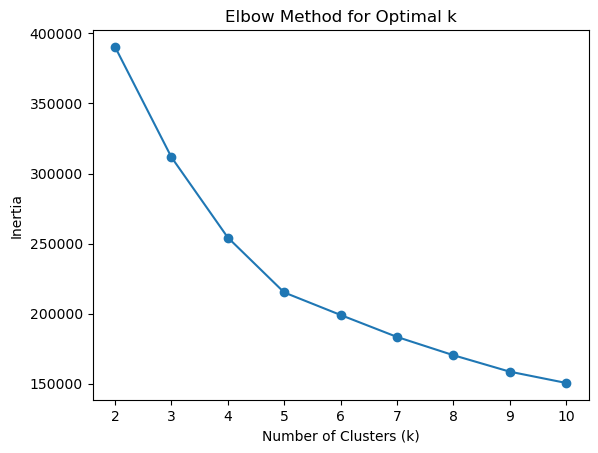

Silhouette Score (K-Means): 0.24


In [11]:
# Elbow Method
inertia = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

# Fit K-Means with chosen k (e.g., k=3)
kmeans = KMeans(n_clusters=3, random_state=42)
df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

# Silhouette Score
print(f"Silhouette Score (K-Means): {silhouette_score(X_scaled, df['kmeans_cluster']):.2f}")

In [12]:
# Fit DBSCAN (tune eps and min_samples)
dbscan = DBSCAN(eps=0.5, min_samples=5)  # Adjust based on data density
df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

# Count clusters (ignore noise labeled as -1)
n_clusters = len(set(df['dbscan_cluster'])) - (1 if -1 in df['dbscan_cluster'] else 0)
print(f"DBSCAN found {n_clusters} clusters (+ noise)")

# Silhouette Score (exclude noise points)
if n_clusters > 1:
    valid_points = df['dbscan_cluster'] != -1
    score = silhouette_score(X_scaled[valid_points], df.loc[valid_points, 'dbscan_cluster'])
    print(f"Silhouette Score (DBSCAN): {score:.2f}")

DBSCAN found 4 clusters (+ noise)
Silhouette Score (DBSCAN): 0.28


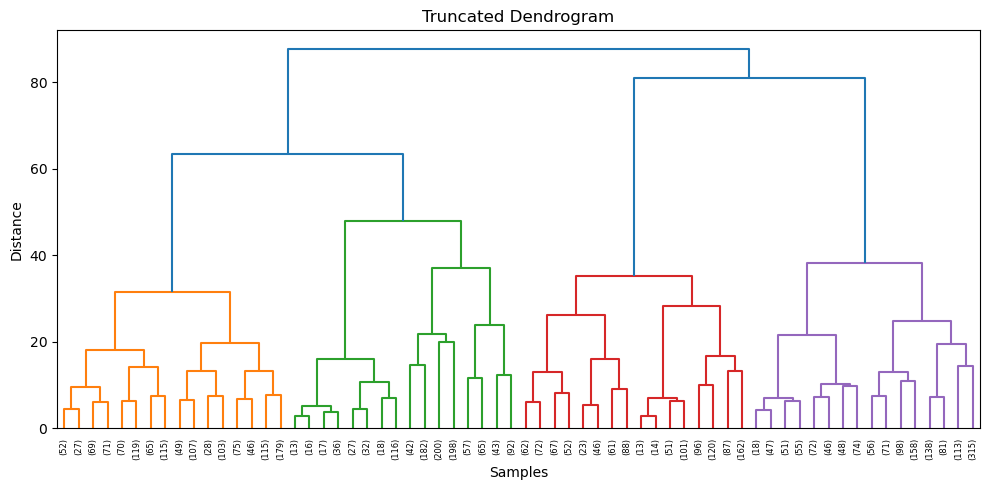

Hierarchical clustering found 3 clusters
Silhouette Score (Hierarchical): 0.21


In [13]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Sample the data (optional: change sample size to avoid memory issues)
sample_size = 5000
df_sample = df.sample(n=min(len(df), sample_size), random_state=42).copy()

# Standardize features
X = df_sample[features].values
X_scaled = StandardScaler().fit_transform(X)

# Linkage matrix (choose method: 'ward', 'single', 'complete', etc.)
Z = linkage(X_scaled, method='ward')

# Dendrogram (truncated for clarity)
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='level', p=5)
plt.title('Truncated Dendrogram')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

# Choose number of clusters (you can try multiple and compare)
k = 3
df_sample['hclust_cluster'] = fcluster(Z, k, criterion='maxclust')

# Count clusters
n_clusters = len(np.unique(df_sample['hclust_cluster']))
print(f"Hierarchical clustering found {n_clusters} clusters")

# Silhouette Score
if n_clusters > 1:
    score = silhouette_score(X_scaled, df_sample['hclust_cluster'])
    print(f"Silhouette Score (Hierarchical): {score:.2f}")


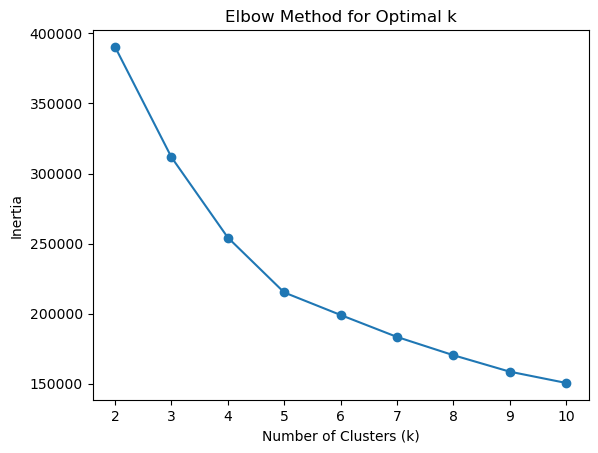

DBSCAN found 4 clusters (+ noise)


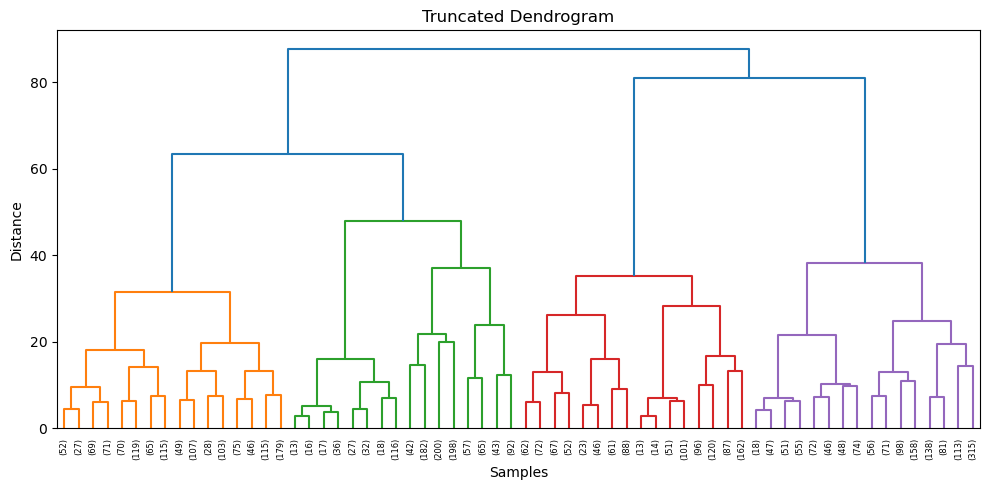


Clustering Performance:
- K-Means (k=3): 0.24
- DBSCAN: 0.28
- Hierarchical (k=3): 0.21


In [14]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Standardize Full Dataset for KMeans & DBSCAN
# -----------------------------
features = ['temperature', 'humidity', 'windSpeed', 'demand']
X_kmeans = StandardScaler().fit_transform(df[features])

# -----------------------------
# Elbow Method for KMeans
# -----------------------------
inertia = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_kmeans)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

# -----------------------------
# Fit K-Means with chosen k
# -----------------------------
k_kmeans = 3
kmeans = KMeans(n_clusters=k_kmeans, random_state=42)
df['kmeans_cluster'] = kmeans.fit_predict(X_kmeans)

# -----------------------------
# Fit DBSCAN (tune eps and min_samples)
# -----------------------------
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['dbscan_cluster'] = dbscan.fit_predict(X_kmeans)

# Count clusters (ignore noise labeled as -1)
dbscan_n_clusters = len(set(df['dbscan_cluster'])) - (1 if -1 in df['dbscan_cluster'] else 0)
print(f"DBSCAN found {dbscan_n_clusters} clusters (+ noise)")

# -----------------------------
# Hierarchical Clustering on Sample
# -----------------------------
sample_size = 5000
df_sample = df.sample(n=min(len(df), sample_size), random_state=42).copy()
X_sample = df_sample[features].values
X_scaled = StandardScaler().fit_transform(X_sample)

Z = linkage(X_scaled, method='ward')

# Dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='level', p=5)
plt.title('Truncated Dendrogram')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

# Assign clusters
k_hier = 3
df_sample['hclust_cluster'] = fcluster(Z, k_hier, criterion='maxclust')

# -----------------------------
# Evaluation: Silhouette Scores
# -----------------------------
print("\nClustering Performance:")
print(f"- K-Means (k={k_kmeans}): {silhouette_score(X_kmeans, df['kmeans_cluster']):.2f}")

if dbscan_n_clusters > 1:
    valid_points = df['dbscan_cluster'] != -1
    print(f"- DBSCAN: {silhouette_score(X_kmeans[valid_points], df.loc[valid_points, 'dbscan_cluster']):.2f}")
else:
    print("- DBSCAN: Not enough clusters for silhouette score.")

print(f"- Hierarchical (k={k_hier}): {silhouette_score(X_scaled, df_sample['hclust_cluster']):.2f}")



Cluster Profiles (K-Means):


,temperature,humidity,windSpeed,demand
kmeans_cluster,,,,
0,72.573290,0.345044,4.767840,5801.709975
1,74.443688,0.719034,7.444567,12927.453495
2,49.796793,0.749188,5.682616,5414.269234


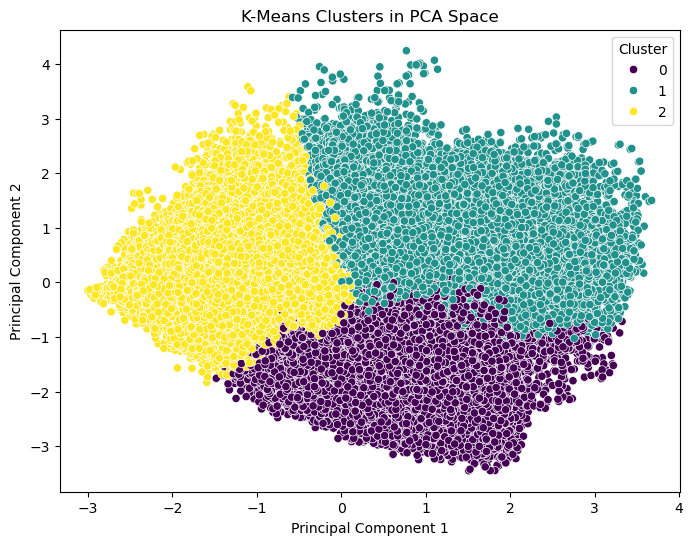

In [15]:
import seaborn as sns
# Analyze mean feature values per cluster
cluster_profile = df.groupby('kmeans_cluster')[features].mean()
print("\nCluster Profiles (K-Means):")
display(cluster_profile)

# Visualize clusters in PCA space
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['kmeans_cluster'], palette='viridis')
plt.title('K-Means Clusters in PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [16]:
# Assign human-readable labels based on profiles
cluster_labels = {
    0: "Low Demand, Cool Weather",
    1: "High Demand, Hot Weather",
    2: "Moderate Demand, Humid"
}
df['cluster_label'] = df['kmeans_cluster'].map(cluster_labels)

# Display sample clusters
print("\nSample Cluster Distribution:")
print(df['cluster_label'].value_counts())


Sample Cluster Distribution:
cluster_label
Moderate Demand, Humid      56272
High Demand, Hot Weather    45157
Low Demand, Cool Weather    27249
Name: count, dtype: int64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")


In [3]:
# Load dataset
df = pd.read_csv("clustered_electricity_demand.csv")

# Parse datetime and sort
df['datetime'] = pd.to_datetime(df['datetime'])
df.sort_values(by=['city', 'datetime'], inplace=True)

# Create lag feature for naive baseline
df['prev_day_demand'] = df.groupby('city')['demand'].shift(24)
df = df.dropna(subset=['prev_day_demand']).copy()

# Define features and target
features = ['hour', 'day_of_week', 'month', 'season',
            'temperature_normalized', 'humidity_normalized',
            'pressure_normalized', 'windSpeed_normalized', 'prev_day_demand']
target = 'demand'

X = df[features]
y = df[target]

# Train-test split based on time
split_date = "2019-06-01"
X_train = X[df['datetime'] < split_date]
X_test = X[df['datetime'] >= split_date]
y_train = y[df['datetime'] < split_date]
y_test = y[df['datetime'] >= split_date]

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


c:\Users\lab\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\lab\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\lab\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


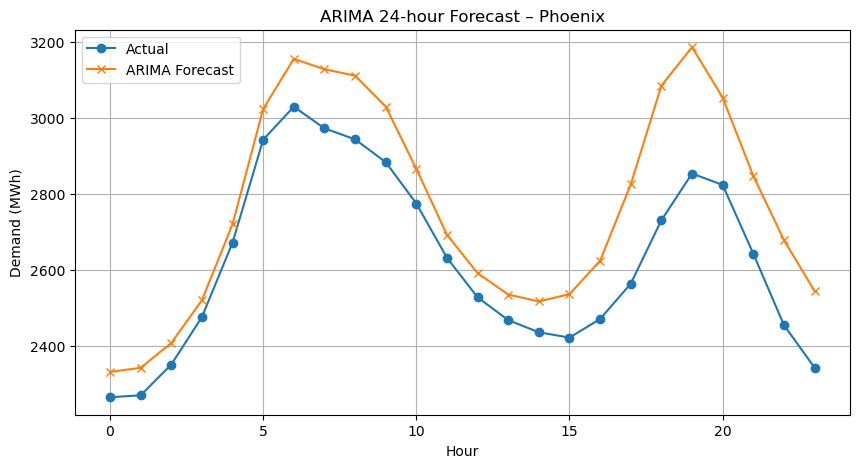

In [21]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Subset city for ARIMA (Phoenix only for time-series modeling)
city_df = df[df['city'] == 'phoenix'].copy()
city_df = city_df.sort_values('datetime')
city_df.set_index('datetime', inplace=True)

# Train/test split for ARIMA (last 24 hours as test)
split_idx = int(len(city_df) * 0.8)
train_arima = city_df['demand'].iloc[:split_idx]
test_arima = city_df['demand'].iloc[split_idx:split_idx + 24]  # next-day forecast

# Fit SARIMA model (can tune these later)
arima_model = SARIMAX(train_arima, order=(1, 1, 1), seasonal_order=(1, 0, 1, 24))
arima_result = arima_model.fit(disp=False)

# Forecast 24 hours
arima_forecast = arima_result.forecast(steps=24)

# Evaluate ARIMA
arima_mae = mean_absolute_error(test_arima, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test_arima, arima_forecast))
arima_mape = np.mean(np.abs((test_arima - arima_forecast) / test_arima)) * 100

# Store in results dictionary
results = {
    'ARIMA (Phoenix)': {
        'MAE': round(arima_mae, 2),
        'RMSE': round(arima_rmse, 2),
        'MAPE': round(arima_mape, 2)
    }
}

# Optional: Plot ARIMA forecast vs. actual
plt.figure(figsize=(10, 5))
plt.plot(test_arima.values, label='Actual', marker='o')
plt.plot(arima_forecast.values, label='ARIMA Forecast', marker='x')
plt.title("ARIMA 24-hour Forecast – Phoenix")
plt.xlabel("Hour")
plt.ylabel("Demand (MWh)")
plt.legend()
plt.grid(True)
plt.show()


In [22]:
# Train 4 models
lr = LinearRegression().fit(X_train_scaled, y_train)
rf = RandomForestRegressor(n_estimators=100, random_state=0).fit(X_train, y_train)
xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=0).fit(X_train, y_train)
mlp = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, random_state=0).fit(X_train_scaled, y_train)


In [ ]:
# Predict
preds = {
    'Linear Regression': lr.predict(X_test_scaled),
    'Random Forest': rf.predict(X_test),
    'XGBoost': xgb.predict(X_test),
    'MLP': mlp.predict(X_test_scaled),
    'Naive Baseline': X_test['prev_day_demand'].values
}

for name, y_pred in preds.items():
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))  # Fixed this line
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    results[name] = {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'MAPE': round(mape, 2)}

# Show combined results
results_df = pd.DataFrame(results).T.reset_index().rename(columns={'index': 'Model'})
results_df


,Model,MAE,RMSE,MAPE
0,ARIMA (Phoenix),141.88,166.72,NaN
1,Linear Regression,1373.55,2381.23,14.17
2,Random Forest,987.70,1772.23,9.17
3,XGBoost,896.57,1565.19,8.44
4,MLP,1009.69,1722.08,10.47
5,Naive Baseline,1385.09,2440.77,12.45


In [27]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# Wrap model
rf_model = RandomForestRegressor(random_state=0)

# Perform Grid Search with 3-fold CV
grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           scoring='neg_mean_absolute_error',
                           cv=3,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

# Best parameters and model
print("Best Parameters:", grid_search.best_params_)
best_rf = grid_search.best_estimator_

# Evaluate on test set
y_pred_rf_cv = best_rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_rf_cv)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred_rf_cv) / y_test)) * 100

print(f"Tuned RF MAE: {mae:.2f}, RMSE: {rmse:.2f}, MAPE: {mape:.2f}%")


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Tuned RF MAE: 1066.44, RMSE: 2440.77, MAPE: 9.90%


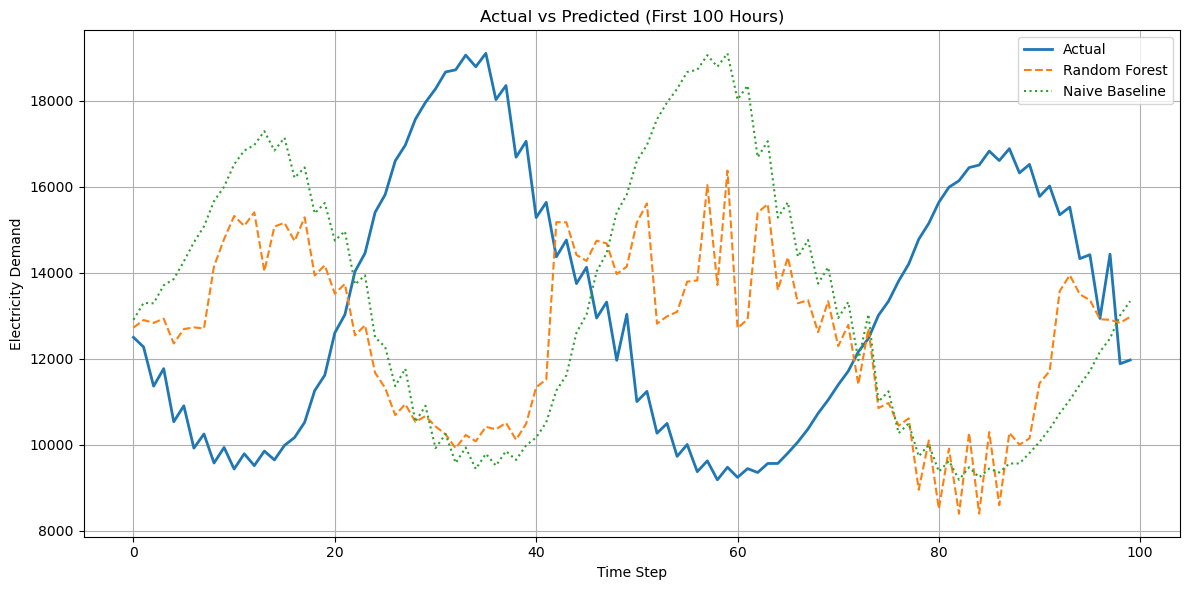

In [28]:
plt.figure(figsize=(12, 6))
plt.plot(y_test.values[:100], label='Actual', linewidth=2)
plt.plot(preds['Random Forest'][:100], label='Random Forest', linestyle='--')
plt.plot(preds['Naive Baseline'][:100], label='Naive Baseline', linestyle=':')
plt.legend()
plt.title('Actual vs Predicted (First 100 Hours)')
plt.xlabel('Time Step')
plt.ylabel('Electricity Demand')
plt.grid(True)
plt.tight_layout()
plt.show()


In [29]:
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save scikit-learn and XGBoost models
joblib.dump(lr, "models/linear_regression.pkl")
joblib.dump(rf, "models/random_forest.pkl")
joblib.dump(xgb, "models/xgboost.pkl")
joblib.dump(mlp, "models/mlp.pkl")
import pickle

with open("models/sarima_phoenix.pkl", "wb") as f:
    pickle.dump(arima_result, f)


In [ ]:
from flask import Flask, request, jsonify
from forecast import get_forecast
from cluster import get_clusters

app = Flask(__name__)

@app.route("/api/forecast", methods=["POST"])
def forecast_route():
    try:
        data = request.get_json()
        if not data:
            return jsonify({"error": "Invalid or missing JSON"}), 400

        city = data.get("city")
        start = data.get("start")
        end = data.get("end")
        models = data.get("models", [])

        if not all([city, start, end]):
            return jsonify({"error": "Missing required parameters"}), 400

        result = get_forecast(city, start, end, models)
        return jsonify(result)

    except Exception as e:
        return jsonify({"error": str(e)}), 500

@app.route("/api/cluster", methods=["POST"])
def cluster_route():
    try:
        data = request.get_json()
        if not data:
            return jsonify({"error": "Invalid or missing JSON"}), 400

        city = data.get("city")
        start = data.get("start")
        end = data.get("end")
        k = int(data.get("k", 3))

        if not all([city, start, end]):
            return jsonify({"error": "Missing required parameters"}), 400

        result = get_clusters(city, start, end, k)
        return jsonify(result)

    except Exception as e:
        return jsonify({"error": str(e)}), 500

@app.route("/")
def home():
    return "✅ Electric Load Forecasting API is running."

if __name__ == "__main__":
    app.run(port=8000, debug=True)
 

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:8000
Press CTRL+C to quit
 * Restarting with stat


SystemExit: 1